In [45]:
SBOX = [0xC, 0x5, 0x6, 0xB, 0x9, 0x0, 0xA, 0xD, 0x3, 0xE, 0xF, 0x8, 0x4, 0x7, 0x1, 0x2]
P = [ 0, 16, 32, 48,  1, 17, 33, 49,  2, 18, 34, 50,  3, 19, 35, 51,
    4, 20, 36, 52,  5, 21, 37, 53,  6, 22, 38, 54,  7, 23, 39, 55,
    8, 24, 40, 56,  9, 25, 41, 57, 10, 26, 42, 58, 11, 27, 43, 59,
    12, 28, 44, 60, 13, 29, 45, 61, 14, 30, 46, 62, 15, 31, 47, 63 ]

def generate_round_keys(key):
    keys = [key]
    kp = key
    for i in range(1, 32):
        ki = kp >> 19 | ((kp << 61) & 0xffffffffffffffffffff)
        head = (ki >> 76) & 0xf
        ki = (ki & 0xfffffffffffffffffff) | (SBOX[head] << 76)
        ki ^= i << 15
        keys.append(ki)
        kp = ki
    return keys

def add_round_key(state, key):
    return state ^ (key >> 16)

def s_box_layer(state):
    result = 0
    for i in range(16):
        result |= SBOX[(state >> (4*i)) & 0xf] << (4*i)
    return result

def p_layer(state):
    result = 0
    for i in range(64):
        result |= ((state >> i) & 1) << P[i]
    return result

def present(plaintext, keys):
    state = plaintext
    for i in range(31):
        state = add_round_key(state, keys[i])
        state = s_box_layer(state)
        state = p_layer(state)
    return add_round_key(state, keys[31])

In [8]:
tests = [
    (0x0000000000000000, 0x00000000000000000000, 0x5579C1387B228445),
    (0x0000000000000000, 0xFFFFFFFFFFFFFFFFFFFF, 0xE72C46C0F5945049),
    (0xFFFFFFFFFFFFFFFF, 0x00000000000000000000, 0xA112FFC72F68417B),
    (0xFFFFFFFFFFFFFFFF, 0xFFFFFFFFFFFFFFFFFFFF, 0x3333DCD3213210D2),
]

for pt, k, expected in tests:
    res = present(pt, generate_round_keys(k))
    assert res == expected, f"FAIL: got {res:016x}, expected {expected:016x}"

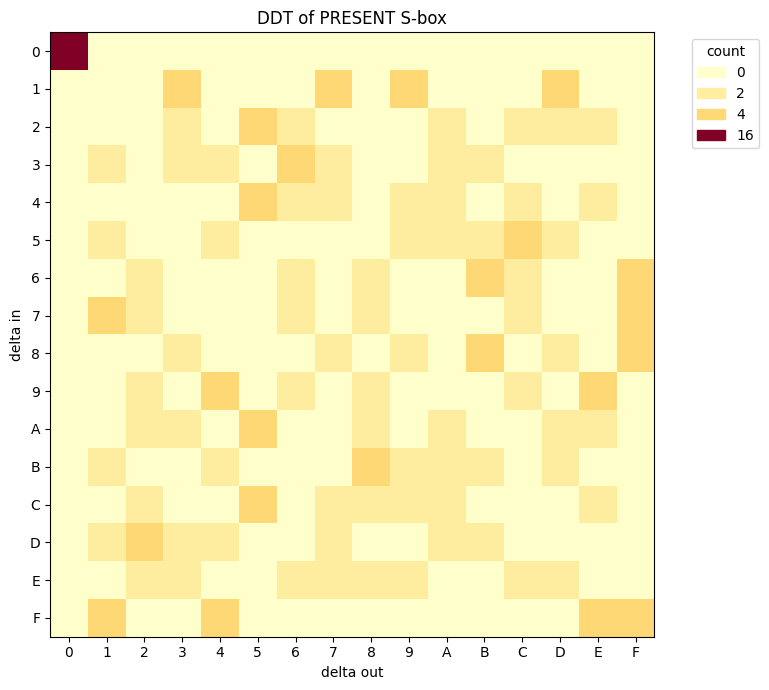

max differential prob: 4/16


In [47]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def build_ddt(sbox):
    n = len(sbox)
    ddt = np.zeros((n, n), dtype=int)
    for di in range(n):
        for x in range(n):
            ddt[di][sbox[x] ^ sbox[x ^ di]] += 1
    return ddt

ddt = build_ddt(SBOX)

cmap = plt.cm.YlOrRd
norm = plt.Normalize(vmin=ddt.min(), vmax=ddt.max())

plt.figure(figsize=(8, 7))
plt.imshow(ddt, cmap=cmap, norm=norm)
plt.xticks(range(16), [f"{i:X}" for i in range(16)])
plt.yticks(range(16), [f"{i:X}" for i in range(16)])
plt.xlabel("delta out")
plt.ylabel("delta in")
plt.title("DDT of PRESENT S-box")

unique_vals = sorted(np.unique(ddt))
legend = [Patch(color=cmap(norm(v)), label=str(v)) for v in unique_vals]
plt.legend(handles=legend, title="count", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

print(f"max differential prob: {ddt[1:].max()}/16")

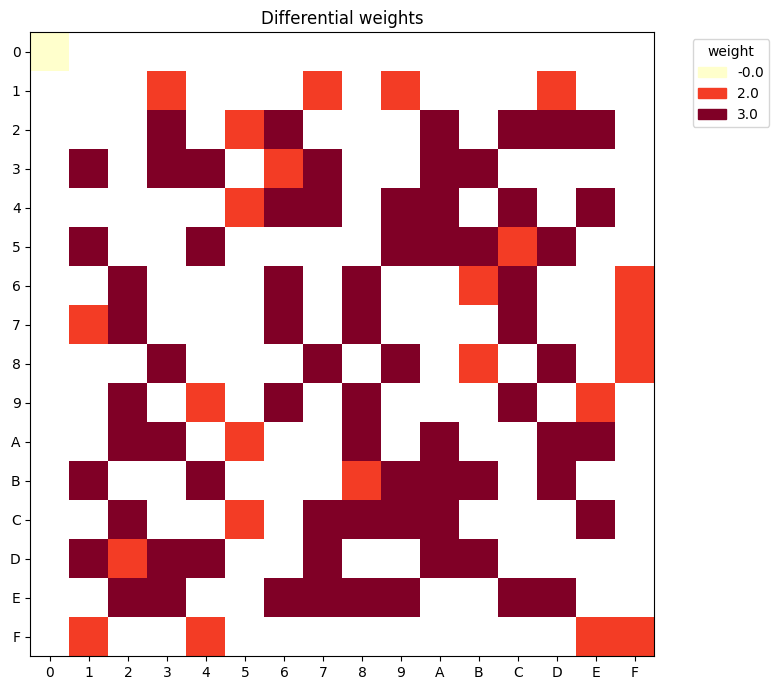

In [10]:
import math
from matplotlib.patches import Patch

weights = np.full((16, 16), np.nan)
for a in range(16):
    for b in range(16):
        if ddt[a][b] > 0:
            weights[a, b] = -math.log2(ddt[a][b] / 16)

cmap = plt.cm.YlOrRd
norm = plt.Normalize(vmin=np.nanmin(weights), vmax=np.nanmax(weights))

plt.figure(figsize=(8, 7))
plt.imshow(weights, cmap=cmap, norm=norm)
plt.xticks(range(16), [f"{i:X}" for i in range(16)])
plt.yticks(range(16), [f"{i:X}" for i in range(16)])
plt.title("Differential weights")

unique_vals = sorted(set(w for row in weights for w in row if not np.isnan(w)))
legend = [Patch(color=cmap(norm(v)), label=str(round(v, 2))) for v in unique_vals]
plt.legend(handles=legend, title="weight", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [19]:
from pysat.formula import CNF
from pysat.solvers import Cadical153

DDT = build_ddt(SBOX)

def diff_var(r, i):
    return 1 + r * 64 + i

def forbid_assignment(x_vars, y_vars, x_val, y_val):
    clause = []
    for i, var in enumerate(x_vars):
        bit = (x_val >> i) & 1
        clause.append(-var if bit == 1 else var)
    for i, var in enumerate(y_vars):
        bit = (y_val >> i) & 1
        clause.append(-var if bit == 1 else var)
    return clause

def sbox_clauses(x_vars, y_vars, DDT):
    clauses = []
    for a in range(16):
        for b in range(16):
            if DDT[a][b] == 0:
                clauses.append(forbid_assignment(x_vars, y_vars, a, b))
    return clauses

In [18]:
def validate_sbox_encoding():
    x_vars = [1, 2, 3, 4]
    y_vars = [5, 6, 7, 8]
    base_clauses = sbox_clauses(x_vars, y_vars, DDT)

    for a in range(16):
        for b in range(16):
            cnf = CNF()
            for c in base_clauses:
                cnf.append(c)
            for i, var in enumerate(x_vars):
                bit = (a >> i) & 1
                cnf.append([var if bit == 1 else -var])
            for i, var in enumerate(y_vars):
                bit = (b >> i) & 1
                cnf.append([var if bit == 1 else -var])

            with Cadical153(bootstrap_with=cnf) as solver:
                sat = solver.solve()

            expected = DDT[a][b] > 0
            assert sat == expected, f"MISMATCH for a={a:#x}, b={b:#x}: SAT={sat}, DDT={DDT[a][b]}"

    print("SAT encoding matches DDT")

validate_sbox_encoding()

SAT encoding matches DDT
